# WEEK 4 — z-Transform Laboratory: Poles, Zeros and Stability

**Name:** BARAKA MARTIN MDEKA
**Registration Number:** 240242436939
**Date:** 25/11/2026


## Pre-lab preparation
**Manual §2.2–2.4**

(a) For H(z)=1/(1−0.9z⁻¹+0.81z⁻²), the characteristic polynomial is z²−0.9z+0.81. Its poles are approximately **0.45 ± j0.7794**, magnitude 0.9, so the causal system is **stable**.

(b) X(z)=1/[(1−0.5z⁻¹)(1−0.25z⁻¹)] = **2/(1−0.5z⁻¹) − 1/(1−0.25z⁻¹)**. For the causal ROC, x[n]=2(0.5)^n u[n]−(0.25)^n u[n].

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
plt.rcParams['figure.figsize']=(9,3.5)
plt.rcParams['axes.grid']=True

## Task 4.1 — A pole-zero plotting function
Implement `zplane`, plot the pole-zero diagram and frequency response for b=[1,1], a=[1,−0.75,0.125].

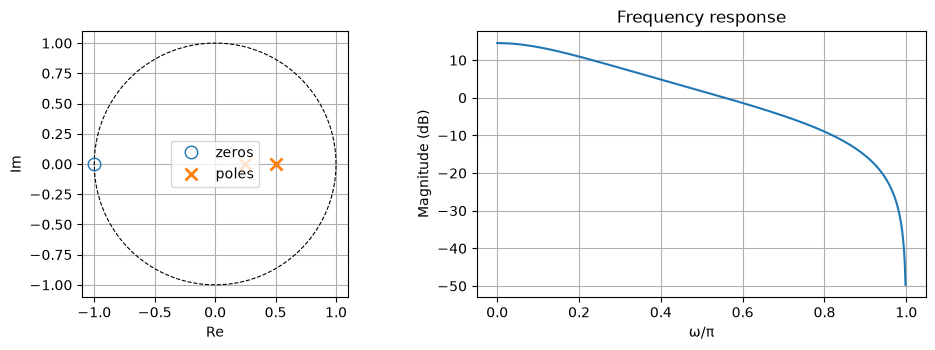

zeros: [-1.] poles: [0.5  0.25] stable: True


In [8]:
def zplane(b,a,ax=None):
    z,p,k = signal.tf2zpk(b,a)
    ax = ax or plt.gca()
    th=np.linspace(0,2*np.pi,400)
    ax.plot(np.cos(th),np.sin(th),'k--',lw=.8)
    ax.plot(z.real,z.imag,'o',mfc='none',ms=9,label='zeros')
    ax.plot(p.real,p.imag,'x',ms=9,mew=2,label='poles')
    ax.set_aspect('equal'); ax.legend(); ax.set_xlabel('Re'); ax.set_ylabel('Im')
    return z,p

b,a=[1,1],[1,-.75,.125]
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,3.6))
z,p=zplane(b,a,ax1)
w,H=signal.freqz(b,a,worN=512)
ax2.plot(w/np.pi,20*np.log10(np.maximum(np.abs(H),1e-12)))
ax2.set_xlabel('ω/π'); ax2.set_ylabel('Magnitude (dB)'); ax2.set_title('Frequency response')
plt.tight_layout(); plt.show()
print('zeros:',z,'poles:',p,'stable:',np.all(np.abs(p)<1))

## Task 4.2 — Inverse z-transform with residuez
Use `signal.residuez`, reconstruct ten samples and compare with `lfilter`. Repeat for Task 4.1 and verify the stated impulse response.

In [9]:
r,poles,k=signal.residuez([1],[1,-.75,.125])
n=np.arange(10)
x_pf=sum(ri*pi**n for ri,pi in zip(r,poles)).real
imp=np.zeros(10); imp[0]=1
x_lf=signal.lfilter([1],[1,-.75,.125],imp)
print('residues:',r,'poles:',poles)
print('Partial fraction samples:',x_pf)
print('lfilter samples:',x_lf)
print('Match:',np.allclose(x_pf,x_lf))
r2,p2,k2=signal.residuez([1,1],[1,-.75,.125])
h_pf=sum(ri*pi**n for ri,pi in zip(r2,p2)).real
h_lf=signal.lfilter([1,1],[1,-.75,.125],imp)
h_expected=6*(.5**n)-5*(.25**n)
print('Task 4.1 residues:',r2,'poles:',p2)
print('Partial fractions:',h_pf)
print('lfilter:',h_lf)
print('Given closed form:',h_expected)
print('Partial fraction equals lfilter:',np.allclose(h_pf,h_lf))
print('Given form equals lfilter:',np.allclose(h_expected,h_lf))

residues: [-1.  2.] poles: [0.25 0.5 ]
Partial fraction samples: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
lfilter samples: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Match: True
Task 4.1 residues: [-5.  6.] poles: [0.25 0.5 ]
Partial fractions: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Given closed form: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Partial fraction equals lfilter: True
Given form equals lfilter: True


## Task 4.3 — Pole position and the impulse response
For p=r·e^(±jπ/4), construct the denominator and compare 40 impulse-response samples and frequency-response magnitude for r=0.5, 0.8, 0.95, 1.0 and 1.05.

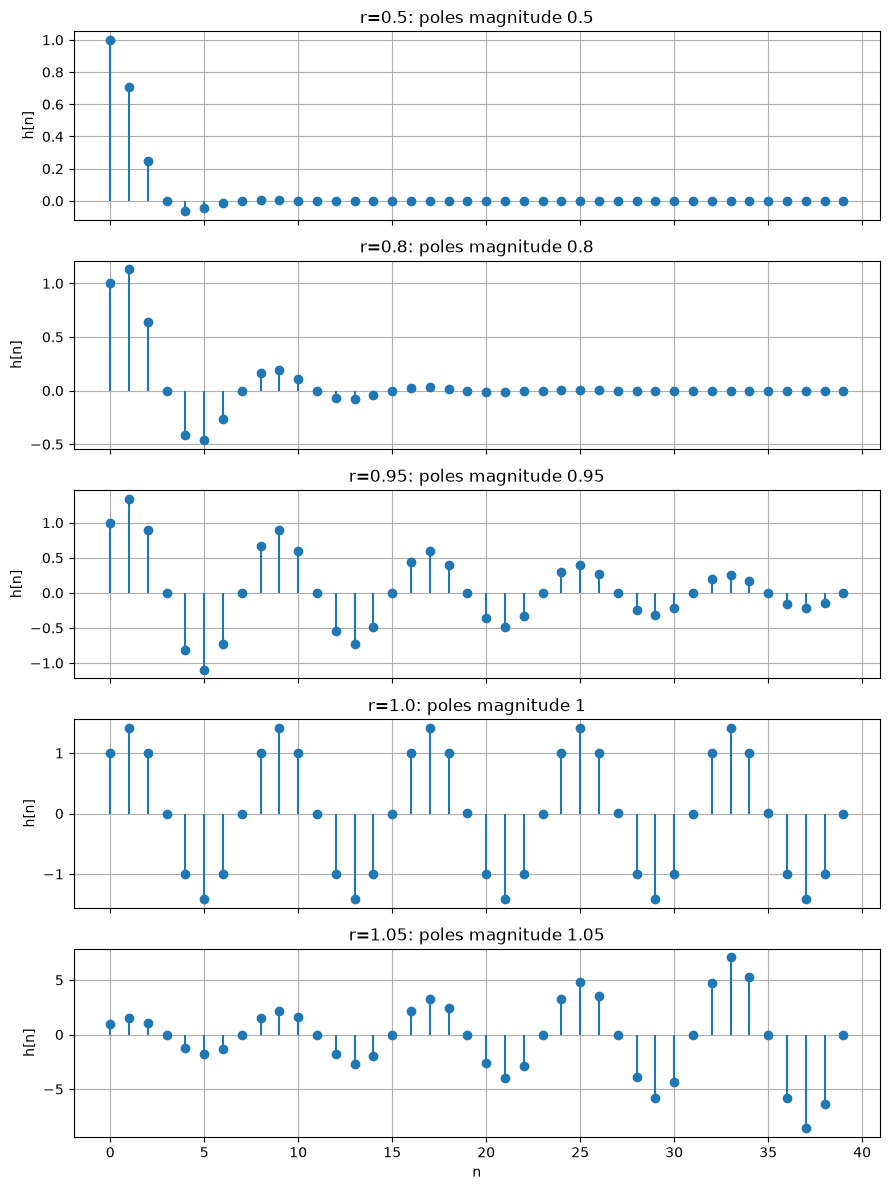

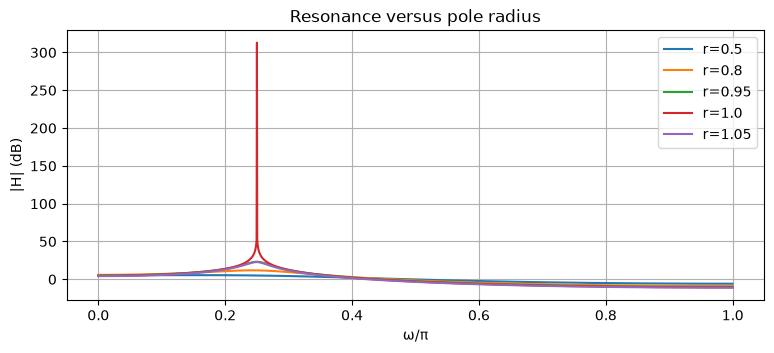

In [10]:
theta=np.pi/4
r_values=[.5,.8,.95,1.0,1.05]
n=np.arange(40)
fig,axes=plt.subplots(len(r_values),1,figsize=(9,12),sharex=True)
for ax,r0 in zip(axes,r_values):
    aa=[1,-2*r0*np.cos(theta),r0**2]
    hh=signal.lfilter([1],aa,np.r_[1.,np.zeros(39)])
    ax.stem(n,hh,basefmt=' ')
    ax.set_title(f'r={r0}: poles magnitude {r0:g}')
    ax.set_ylabel('h[n]')
axes[-1].set_xlabel('n'); plt.tight_layout(); plt.show()

plt.figure()
for r0 in r_values:
    aa=[1,-2*r0*np.cos(theta),r0**2]
    w,H=signal.freqz([1],aa,worN=2048)
    plt.plot(w/np.pi,20*np.log10(np.maximum(abs(H),1e-10)),label=f'r={r0}')
plt.xlabel('ω/π'); plt.ylabel('|H| (dB)'); plt.title('Resonance versus pole radius')
plt.legend(); plt.show()

**Observation:** for r<1 the impulse response decays; as r approaches 1 the decay becomes slower and the resonance becomes narrower/sharper. At r=1 the response is sustained (marginal, not BIBO stable). At r=1.05 the response grows and the causal system is unstable. Oscillation frequency is set by θ=π/4.

## Task 4.4 — Stability of given systems
Classify each transfer function using pole locations and impulse-response growth. H4 is FIR.

H1 poles= [0.8+0.5j 0.8-0.5j] stable= True max |h|= 1.6700000000000004
H2 poles= [2.  0.5] stable= False max |h|= 1125899906842624.0
H3 poles= [-1.   0.5] stable= False max |h|= 1.0
H4 poles= [] stable= True max |h|= 1.0


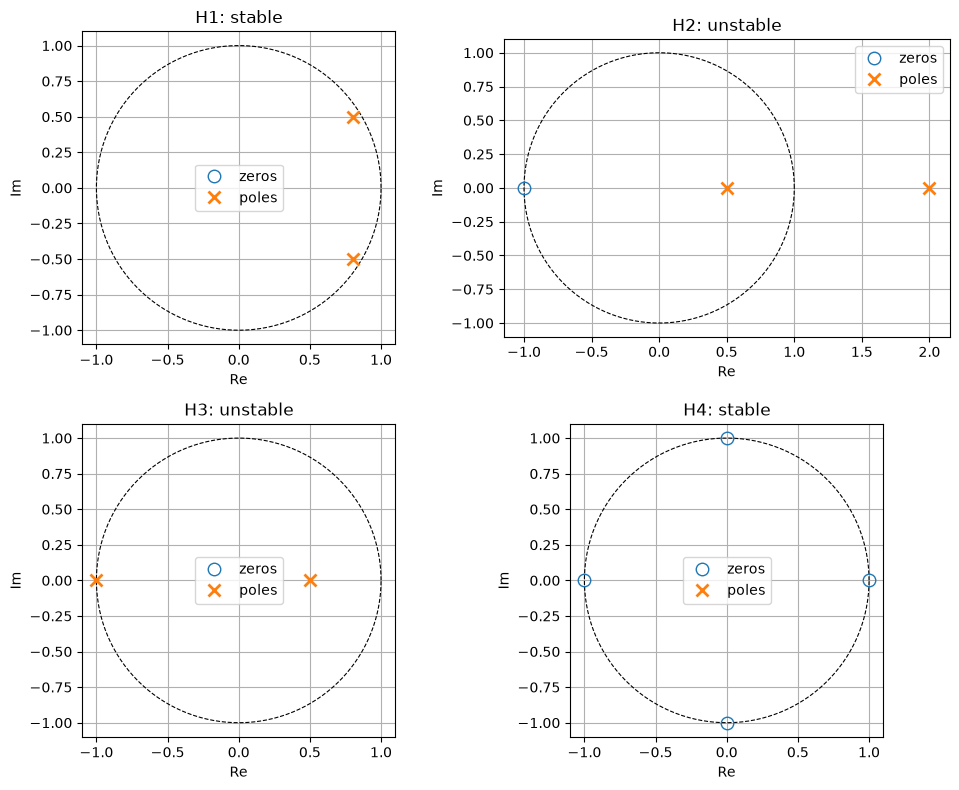

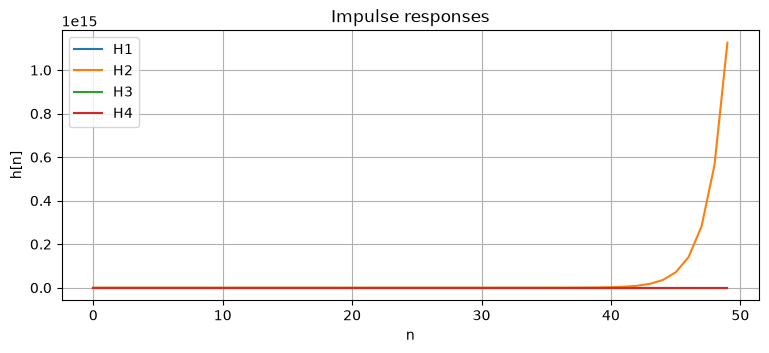

In [11]:
systems={
 'H1':([1],[1,-1.6,.89]),
 'H2':([1,1],[1,-2.5,1]),
 'H3':([1],[1,.5,-.5]),
 'H4':([1,0,0,0,-1],[1])
}
fig,axes=plt.subplots(2,2,figsize=(10,8))
for (name,(bb,aa)),ax in zip(systems.items(),axes.ravel()):
    zz,pp=zplane(bb,aa,ax)
    stable=np.all(np.abs(pp)<1) if len(pp) else True
    h=signal.lfilter(bb,aa,np.r_[1.,np.zeros(49)])
    print(name,'poles=',pp,'stable=',stable,'max |h|=',np.max(np.abs(h)))
    ax.set_title(f'{name}: '+('stable' if stable else 'unstable'))
plt.tight_layout(); plt.show()

plt.figure()
for name,(bb,aa) in systems.items():
    h=signal.lfilter(bb,aa,np.r_[1.,np.zeros(49)])
    plt.plot(h,label=name)
plt.xlabel('n'); plt.ylabel('h[n]'); plt.title('Impulse responses')
plt.legend(); plt.show()

## Task 4.5 — Design a resonator
Peak at 1 kHz for fs=8 kHz with r=0.97; place zeros at z=+1 and z=−1. The pole angle is θ=2π(1000/8000)=π/4. Denominator is 1−2r cos(θ)z⁻¹+r²z⁻²; numerator for zeros ±1 is 1−z⁻².

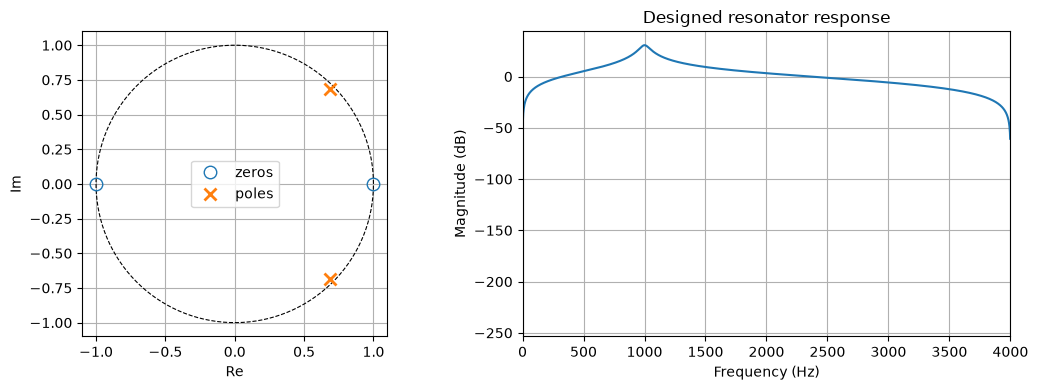

zeros: [ 1. -1.] poles: [0.68589358+0.68589358j 0.68589358-0.68589358j] stable: True


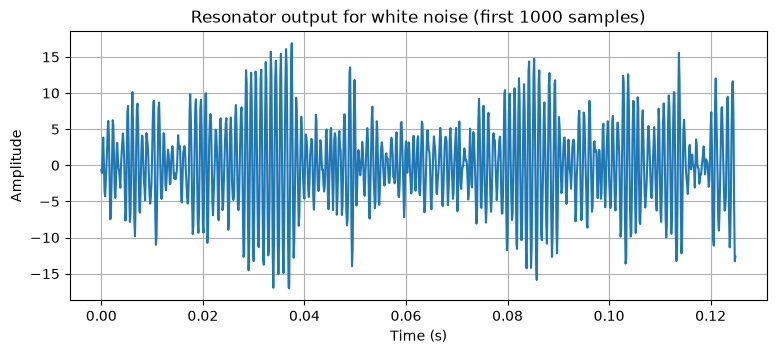

In [12]:
fs=8000
f0=1000
r0=.97
theta=2*np.pi*f0/fs
b_res=[1,0,-1]
a_res=[1,-2*r0*np.cos(theta),r0**2]
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(11,4))
z,p=zplane(b_res,a_res,ax1)
f,H=signal.freqz(b_res,a_res,fs=fs,worN=2048)
ax2.plot(f,20*np.log10(np.maximum(np.abs(H),1e-12)))
ax2.set_xlim(0,fs/2); ax2.set_xlabel('Frequency (Hz)'); ax2.set_ylabel('Magnitude (dB)')
ax2.set_title('Designed resonator response')
plt.tight_layout(); plt.show()
print('zeros:',z,'poles:',p,'stable:',np.all(np.abs(p)<1))
rng=np.random.default_rng(4)
noise=rng.standard_normal(fs)
y=signal.lfilter(b_res,a_res,noise)
plt.plot(np.arange(1000)/fs,y[:1000])
plt.xlabel('Time (s)'); plt.ylabel('Amplitude'); plt.title('Resonator output for white noise (first 1000 samples)')
plt.show()
# In Jupyter, uncomment to listen:
# from IPython.display import Audio, display
# display(Audio(y,rate=fs))

## Analysis questions — suggested answers
1. Increasing r toward 1 moves the poles closer to the unit circle, increases resonant buildup and narrows the resonance bandwidth. Smaller r gives a broader, less pronounced peak and faster decay.
2. A pole exactly on the unit circle produces a non-decaying oscillatory component (for a simple pole); the impulse response is not absolutely summable, so the causal system is not BIBO stable.
3. A zero at z=+1 gives a null at DC (ω=0); a zero at z=−1 gives a null at Nyquist (ω=π, fs/2). Suppressing both ends leaves a band-pass-like resonant peak between them.
4. Stability requires all poles strictly inside the unit circle. H1 has complex poles with magnitude √0.89≈0.943 and is stable. H2 has poles at 2 and 0.5, so it is unstable. H3 has poles at approximately 0.5 and −1; the pole at −1 is on the unit circle, so it is not BIBO stable. H4 is FIR and stable because it has no feedback poles outside the finite-polynomial representation (its impulse response is finite).

## Checkpoint and submission
- Show stability classifications from Task 4.4 and the resonator response from Task 4.5.
- Submit Tasks 4.1–4.5, plots, answers and AI-use statement as `COU07506_Week04_<RegNo>.ipynb`.
- Have the mini-project proposal draft ready for discussion with your group.

**AI-use statement:** AI assistance was used to structure notebook code and draft explanations. Verify all numerical results and disclose assistance as required.